<a href="https://colab.research.google.com/github/Fqrina/ai-archive/blob/main/time_traveler.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Time Traveler — Starter Notebook

**Platform:** hAIplay (haiplay.haippy.co)

Prediksi apakah setiap produk adalah **cacat (1)** atau **tidak cacat (0)**.
Data training mencakup periode sebelum dan sesudah perubahan operasional yang tidak didokumentasikan.

**Metric:** Macro F1-Score

**Format Submission:**
```
id,defect
0,0
1,1
2,0
```

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded!')

Libraries loaded!


## 2. Load Data

In [ ]:
train = pd.read_csv('drift_train2.csv')
test  = pd.read_csv('drift_test2.csv')

print('Train shape:', train.shape)
print('Test shape :', test.shape)
train.head()

Train shape: (6000, 14)
Test shape : (1500, 13)


,id,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,defect
0,0,-1.6550,-1.0875,-1.1727,0.4005,-0.3729,0.1897,1.2646,1.2869,0.7128,-0.6762,-1.1324,-1.2222,0
1,1,-0.5158,-0.0771,-1.4584,-1.7017,0.4586,-2.7775,-0.2656,0.6387,-1.4780,-1.6694,-1.1409,0.9720,1
2,2,-0.1947,-2.8044,-0.6350,1.5208,1.4756,0.9451,-0.3571,-2.7674,0.2544,-0.2640,0.1152,2.3135,0
3,3,0.2755,0.4145,0.9076,-0.3849,-0.9965,-1.1061,1.1504,0.7568,-0.7343,1.7290,0.2765,-2.0103,1
4,4,0.9088,-0.2092,-1.9932,0.7732,-0.5172,-0.5885,0.8848,-3.2887,-1.9160,-0.6368,0.3737,-0.9977,1


## 3. Exploratory Data Analysis (EDA)

Luangkan waktu untuk memahami data sebelum modeling.

<Axes: xlabel='sensor_2', ylabel='sensor_5'>

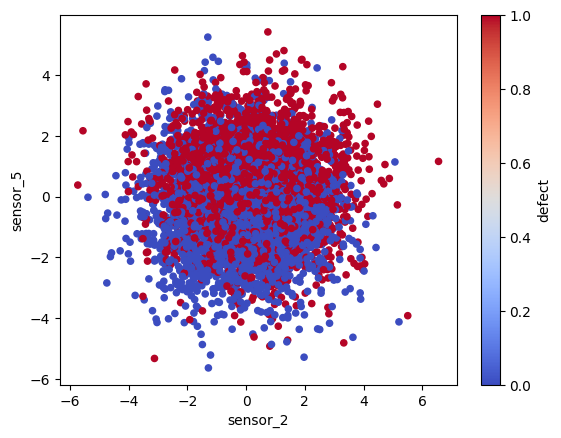

In [ ]:
train.plot.scatter(x="sensor_2", y="sensor_5", c="defect", cmap="coolwarm")

In [ ]:
train.head()

,id,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,defect
0,0,-1.6550,-1.0875,-1.1727,0.4005,-0.3729,0.1897,1.2646,1.2869,0.7128,-0.6762,-1.1324,-1.2222,0
1,1,-0.5158,-0.0771,-1.4584,-1.7017,0.4586,-2.7775,-0.2656,0.6387,-1.4780,-1.6694,-1.1409,0.9720,1
2,2,-0.1947,-2.8044,-0.6350,1.5208,1.4756,0.9451,-0.3571,-2.7674,0.2544,-0.2640,0.1152,2.3135,0
3,3,0.2755,0.4145,0.9076,-0.3849,-0.9965,-1.1061,1.1504,0.7568,-0.7343,1.7290,0.2765,-2.0103,1
4,4,0.9088,-0.2092,-1.9932,0.7732,-0.5172,-0.5885,0.8848,-3.2887,-1.9160,-0.6368,0.3737,-0.9977,1


In [ ]:
train.corr()

,id,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,defect
id,1.000000,-0.002624,0.014560,-0.000457,0.010220,0.002204,-0.010817,-0.003821,-0.000638,0.011724,-0.013388,0.009661,0.016730,0.043599
sensor_1,-0.002624,1.000000,-0.023772,-0.009763,-0.005957,-0.012281,-0.008856,0.000996,-0.005601,0.013318,-0.002629,-0.004653,0.004433,0.118092
sensor_2,0.014560,-0.023772,1.000000,-0.007085,0.004130,0.013695,-0.019442,0.004787,-0.007022,0.030332,-0.003764,0.002042,0.007285,0.202761
sensor_3,-0.000457,-0.009763,-0.007085,1.000000,-0.028296,0.000954,0.008808,0.034865,-0.012042,-0.023268,-0.012539,-0.007398,-0.001957,-0.152217
sensor_4,0.010220,-0.005957,0.004130,-0.028296,1.000000,0.020919,-0.020591,-0.018788,0.009660,0.014309,0.003026,-0.013186,-0.003230,0.273988
sensor_5,0.002204,-0.012281,0.013695,0.000954,0.020919,1.000000,0.001227,-0.007114,0.018934,0.023195,-0.008870,0.006963,-0.019370,0.212052
sensor_6,-0.010817,-0.008856,-0.019442,0.008808,-0.020591,0.001227,1.000000,0.017010,0.002378,0.001937,-0.006330,0.002839,-0.002162,-0.007570
sensor_7,-0.003821,0.000996,0.004787,0.034865,-0.018788,-0.007114,0.017010,1.000000,0.003777,-0.005961,-0.005389,0.005734,0.014402,-0.029343
sensor_8,-0.000638,-0.005601,-0.007022,-0.012042,0.009660,0.018934,0.002378,0.003777,1.000000,-0.001793,-0.013153,0.002532,-0.011937,-0.003358
sensor_9,0.011724,0.013318,0.030332,-0.023268,0.014309,0.023195,0.001937,-0.005961,-0.001793,1.000000,-0.013727,-0.003437,0.002068,0.021366


<Axes: >

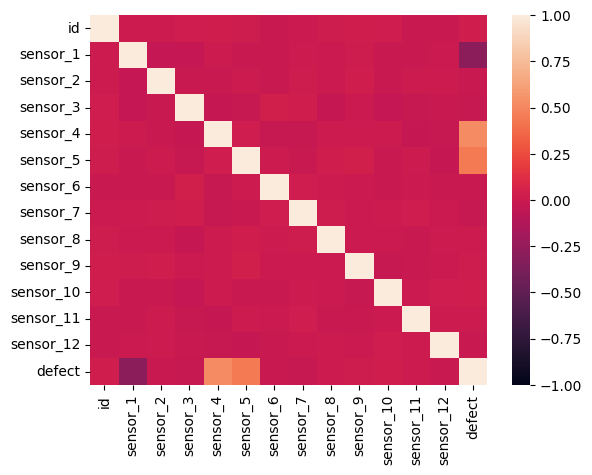

In [ ]:
import seaborn as sns
sns.heatmap(train[3000:].corr(), vmax=1, vmin=-1)

In [ ]:
1,2,3 $ 1,4,5

In [ ]:
train.describe()

,id,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,defect
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,2999.500000,-0.014451,0.002445,0.009438,0.033888,-0.012249,-0.024167,-0.008190,-0.018743,-0.003218,-0.002622,0.007347,-0.044124,0.492667
std,1732.195139,1.515557,1.528666,1.506873,1.510649,1.509565,1.493730,1.503608,1.515817,1.520396,1.500467,1.497696,1.479262,0.499988
min,0.000000,-5.375700,-5.730800,-5.463800,-6.383400,-5.636600,-5.029800,-5.626400,-5.687600,-4.964500,-4.788200,-5.319100,-5.142400,0.000000
25%,1499.750000,-1.029350,-1.031775,-1.004450,-0.968150,-1.010325,-0.986575,-1.006125,-1.015375,-1.029775,-1.004725,-1.007300,-1.032150,0.000000
50%,2999.500000,0.004250,-0.011850,0.004150,0.044200,0.014800,-0.023000,-0.010400,-0.008650,-0.021150,-0.009250,-0.006500,-0.029250,0.000000
75%,4499.250000,1.018150,1.026075,1.006900,1.058675,0.995950,0.983650,0.993875,0.988525,1.032125,1.007750,1.009075,0.963050,1.000000
max,5999.000000,5.425500,6.552200,5.742800,6.212300,5.412900,5.481000,5.921200,5.262500,5.149200,6.122000,5.804400,5.653500,1.000000


In [ ]:
train.head(50)

,id,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,defect
0,0,-1.6550,-1.0875,-1.1727,0.4005,-0.3729,0.1897,1.2646,1.2869,0.7128,-0.6762,-1.1324,-1.2222,0
1,1,-0.5158,-0.0771,-1.4584,-1.7017,0.4586,-2.7775,-0.2656,0.6387,-1.4780,-1.6694,-1.1409,0.9720,1
2,2,-0.1947,-2.8044,-0.6350,1.5208,1.4756,0.9451,-0.3571,-2.7674,0.2544,-0.2640,0.1152,2.3135,0
3,3,0.2755,0.4145,0.9076,-0.3849,-0.9965,-1.1061,1.1504,0.7568,-0.7343,1.7290,0.2765,-2.0103,1
4,4,0.9088,-0.2092,-1.9932,0.7732,-0.5172,-0.5885,0.8848,-3.2887,-1.9160,-0.6368,0.3737,-0.9977,1
5,5,-1.4951,-1.5786,-0.1759,1.0125,-2.1750,-3.1206,-0.4461,-0.5730,-1.3635,0.9176,1.2069,-0.8463,0
6,6,-0.5167,0.8550,-0.6438,-2.1047,-0.1014,-1.3563,0.4879,-0.7578,-0.2837,0.7791,-0.1872,-0.9510,1
7,7,-1.5097,2.5816,1.6599,-2.2555,-1.5787,0.8760,-0.8825,0.0227,1.2210,0.1932,-0.1938,-0.7104,0
8,8,-0.1296,0.5800,2.6021,1.5975,-0.2992,1.3748,0.1757,-2.2221,-0.1600,1.4920,-0.8945,1.4040,0
9,9,-0.4600,0.0397,-1.7867,3.1053,0.6802,1.5126,-0.6791,-2.1951,1.8174,-1.0678,2.4781,-0.2567,1


In [ ]:
FEATURE_SELECTED = ['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5',
       'sensor_6', 'sensor_7',
                    'sensor_8', 'sensor_9',
                    'sensor_10',
       'sensor_11', 'sensor_12'
       ]

In [ ]:
train["defect"].unique()

array([0, 1])

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val = train_test_split(train[FEATURE_SELECTED], train["defect"], test_size=0.2, shuffle=False)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_trainscaled = scaler.fit_transform(x_train)
valscaled = scaler.transform(x_val)

## 4. Modeling — Percobaan Pertama

Latih model klasifikasi pada seluruh data training.
Evaluasi dengan cross-validation dan catat hasilnya.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
rfc = RandomForestClassifier(class_weight="balanced")
rfc.fit(x_trainscaled, y_train)

RandomForestClassifier(class_weight='balanced')

In [ ]:
from sklearn.metrics import f1_score
f1_score(rfc.predict(valscaled), y_val)

0.5695364238410596

In [ ]:
from sklearn.linear_model import LogisticRegression
log = LogisticRegression()
log.fit(x_trainscaled, y_train)
f1_score(log.predict(valscaled), y_val)

0.5934959349593496

## 5. Analisis Performa Model

Setelah training, coba evaluasi model secara lebih dalam:

- Bagaimana performa model jika kamu split train/validation berdasarkan urutan baris (bukan random)?
- Apakah model yang dilatih pada data awal (id kecil) bekerja baik pada data akhir (id besar)?
- Apakah sebaliknya?

> **Hint:** Coba bagi training data menjadi dua bagian berdasarkan `id`, lalu uji cross-directional performance.


1. shuffle=False
2. worse 10%
3. engga
4. kalau train di id besar, 2% better than train di id kecil

In [ ]:
trainq3 = train[:4000][FEATURE_SELECTED]
trainq4 = train[4000:][FEATURE_SELECTED]
yq3 = train[:4000]["defect"]
yq4 = train[4000:]["defect"]

In [ ]:
log.fit(trainq3, yq3)
f1_score(log.predict(trainq4), yq4)

0.5067737079779228

In [ ]:
trainq1 = train[:2000][FEATURE_SELECTED]
trainq2 = train[2000:][FEATURE_SELECTED]
yq1 = train[:2000]["defect"]
yq2 = train[2000:]["defect"]

In [ ]:
log.fit(trainq2, yq2)
f1_score(log.predict(trainq1), yq1)

0.5215163934426229

In [ ]:
train4 = train[3000:5500][["sensor_1", "sensor_4", "sensor_5"]]
val4 = train[5500:6000][["sensor_1", "sensor_4", "sensor_5"]]
y4 = train[3000:5500]["defect"]
yval4 = train[5500:6000]["defect"]
log.fit(train4, y4)
f1_score(log.predict(val4), yval4)

0.9506398537477148

In [ ]:
rfc.fit(train4, y4)
f1_score(rfc.predict(val4), yval4)

0.9326047358834244

## 6. Evaluasi

Ukur Macro F1-Score model terbaikmu dengan cara yang tepat untuk data temporal.

> **Hint:** Random cross-validation mungkin memberikan estimasi yang terlalu optimis. Pertimbangkan time-based split untuk evaluasi yang lebih realistis.

In [ ]:
f1_score(log.predict(trainq1), yq1)

0.5215163934426229

## 7. Prediksi & Submission

In [ ]:
features = ["sensor_1", "sensor_4", "sensor_5"]
preds = log.predict(test[features])
submission = pd.DataFrame({
    'id'    : test['id'],
    'defect': preds
})

submission.to_csv('submission.csv', index=False)
print('submission.csv tersimpan!')
submission.head(10)

submission.csv tersimpan!


,id,defect
0,0,0
1,1,1
2,2,1
3,3,0
4,4,0
5,5,0
6,6,0
7,7,1
8,8,0
9,9,1


## 8. Ide Improvement

Sudah submit tapi ingin skor lebih tinggi? Pertanyaan untuk dipikirkan:

1. Apakah semua data training sama-sama berguna untuk memprediksi test?
2. Jika ada perubahan di suatu titik, bagaimana cara menemukannya?
3. Apakah data yang lebih lama bisa membantu atau justru mengganggu?
4. Apa yang terjadi jika kamu hanya menggunakan sebagian data training?
5. Bisakah kamu memberi bobot lebih pada data yang lebih relevan dengan test?

In [ ]:
linearregression, logistic, knn, kmeans , mlpclassif/regressor.
decisiontree

In [ ]:
standardscaler, pca high dimension, transformer

In [ ]:
1.5iqr+q3